In [1]:
!gdown 1kh3Fz_JmR75a22_1mxfcWMRTRcHGK-iA

Downloading...
From: https://drive.google.com/uc?id=1kh3Fz_JmR75a22_1mxfcWMRTRcHGK-iA
To: /content/train.csv
100% 461k/461k [00:00<00:00, 8.28MB/s]


In [2]:
import pandas as pd
df=pd.read_csv("train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


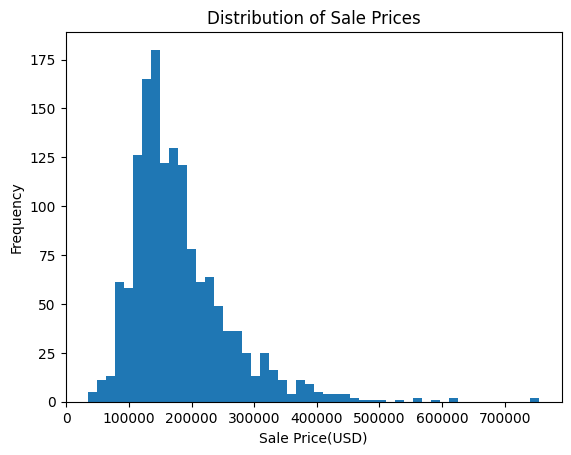

In [3]:
import matplotlib.pyplot as plt
#print(df["SalePrice"].describe());
plt.hist(df["SalePrice"], bins=50)
plt.xlabel("Sale Price(USD)")
plt.ylabel("Frequency")
plt.title("Distribution of Sale Prices")
plt.savefig("price_hist.png", dpi=150)
plt.show()


In [29]:
import numpy as np
print(df["SalePrice"].skew())
print(np.log1p(df["SalePrice"]).skew())

1.8828757597682129
0.12134661989685333


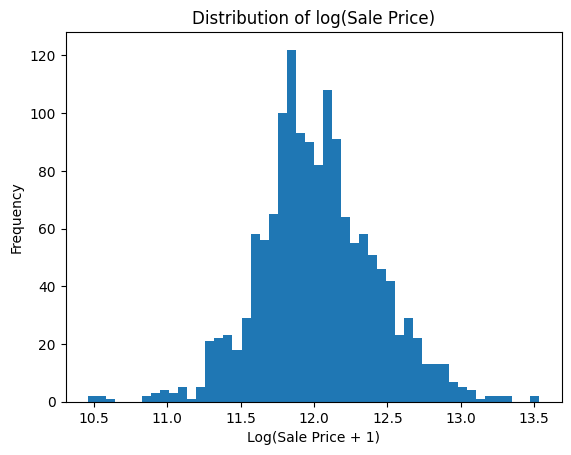

In [31]:
plt.hist(np.log1p(df["SalePrice"]), bins=50)
plt.xlabel("Log(Sale Price + 1)")
plt.ylabel("Frequency")
plt.title("Distribution of log(Sale Price)")
plt.savefig("log_price_hist.png", dpi=150)
plt.show()

In [35]:
missing=df.isnull().sum()
missing=missing[missing>0]
missing.sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [5]:
# 1. Select only the numeric columns
numeric_df = df.select_dtypes("number")

# 2. Calculate the correlation matrix
correlation = numeric_df.corr()

# 3. Select SalePrice correlations and sort in descending order
saleprice_corr = correlation["SalePrice"].sort_values(ascending=False)

saleprice_corr

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
